# Model Training & Analysis

Trains the final LightGBM model using the tuned hyperparameters, evaluates it,
and registers it with MLflow.

**Pipeline overview**
1. Load `model_dataset.parquet` & tuned hyperparameters
2. Train/validation split (identical to Notebook 2 — same `RANDOM_STATE`/`TEST_SIZE`)
3. Train the final model with early stopping
4. Find the optimal classification threshold (F1-maximizing)
5. Compute & export evaluation metrics
6. Feature importance analysis
7. ROC & Precision-Recall curves
8. MLflow tracking & model registration

**Outputs:**
- `data/Model-Training/ModelOutput/classification_report_optimal_threshold.{txt,csv}`
- `data/Model-Training/ModelOutput/lgbm_feature_importance.xlsx`
- `data/Model-Training/ModelOutput/model_evaluation_curves.png`
- MLflow run + registered model `HomeCredit_Scorecard_Model`

## 1. Imports & Configuration

In [ ]:
import os
import json
import pandas as pd
import numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, roc_auc_score, log_loss,
    precision_score, recall_score, f1_score,
    precision_recall_curve, classification_report,
    roc_curve, auc,
)
PROJECT_ROOT = os.environ.get("HOMECREDIT_PROJECT_ROOT", r"a:\Dominic\My Projects\Home Credit")
DATA_ROOT = os.environ.get("HOMECREDIT_DATA_ROOT", r"a:\Dominic\My Projects\Home Credit\data")
SRC_ROOT  = os.environ.get("HOMECREDIT_SRC_DIR", r"a:\Dominic\My Projects\Home Credit\src")

MDS_DIR = os.path.join(DATA_ROOT, "Model-Training", "ModelDataset")
HPO_DIR = os.path.join(DATA_ROOT, "Model-Training", "HyperParameters")
VAR_SELECTION_DIR = os.path.join(DATA_ROOT, "Model-Training", "Variable-Selection")

PATH_MODEL_DATASET = os.path.join(MDS_DIR, "model_dataset_final.parquet")
PATH_BEST_HYPERPARS = os.path.join(HPO_DIR, "LightGBM_v1", "lgbm_resolved_best.json")
# use v1 feature importance table to select features for v2 model training
PATH_FEATURE_IMPORTANCE = os.path.join(DATA_ROOT, "Model-Training", "ModelOutput", "LightGBM_v3")
PATH_SELECTED_FEATURES = os.path.join(VAR_SELECTION_DIR, "numeric_selection_metrics_full_df.xlsx")

MODEL_OUTPUT_DIR = os.path.join(DATA_ROOT, "Model-Training", "ModelOutput", "LightGBM_v4")
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

# ── MUST match Notebook 2 exactly — same split = comparable AUC/metrics ──────
RANDOM_STATE = 1994
TEST_SIZE    = 0.20

# ── MLflow toggle ─────────────────────────────────────────────────────────
ENABLE_MLFLOW = False
MLFLOW_TRACKING_URI = f"file:{DATA_ROOT}/mlruns".replace('\\', '/')
MLFLOW_EXPERIMENT_NAME = "Home_Credit_Default_Risk"
MLFLOW_REGISTERED_MODEL_NAME = "HomeCredit_Scorecard_Model"
# Derived from MODEL_OUTPUT_DIR ("LightGBM_v4") -- used as the run name and a
# "model_name" tag so this model version is distinguishable from other
# LightGBM_vN runs in the MLflow UI (Runs table, and the Chart tab's legend/axis).
MLFLOW_RUN_NAME = os.path.basename(MODEL_OUTPUT_DIR)

## 2. Load Data & Tuned Hyperparameters

> **Note:** uses all features where `cumulative importance <= 80%` from first model (v1).

In [14]:
model_dataset = pd.read_parquet(PATH_MODEL_DATASET)
importance_df = pd.read_excel(os.path.join(PATH_FEATURE_IMPORTANCE, 'lgbm_feature_importance.xlsx'))

importance_df = importance_df.sort_values(by='importance', ascending=False)
feature_cols = importance_df[importance_df['cumulative_importance'] <= 0.8]['feature'].tolist()
print(f"Selected {len(feature_cols)} features for model training (cumulative importance <= 0.8)")

X = model_dataset[['SK_ID_CURR'] + feature_cols]
y = model_dataset['TARGET']
X.set_index('SK_ID_CURR', inplace=True)

with open(PATH_BEST_HYPERPARS) as f:
    resolved_best = json.load(f)

print("Loaded hyperparameters:")
print(json.dumps(resolved_best, indent=2))

Selected 15 features for model training (cumulative importance <= 0.8)
Loaded hyperparameters:
{
  "colsample_bytree": 0.21807117503284643,
  "learning_rate": 0.027563061296715565,
  "max_depth": 9,
  "min_child_samples": 500,
  "min_split_gain ": 0.03885695338663592,
  "n_estimators": 680,
  "num_leaves": 113,
  "reg_alpha": 2.4526747630907937,
  "reg_lambda": 0.46307761596584635
}


In [15]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"X_train: {X_train.shape}  |  X_val: {X_val.shape}")

X_train: (246008, 15)  |  X_val: (61503, 15)


## 3. Train the Final Model

In [16]:
final_model = lgb.LGBMClassifier(
    objective='binary',
    boosting_type='goss',
    seed=42,
    verbose=-1,
    **resolved_best,
)

print("Training the final optimized model...")
final_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=True)],
)

# This is THE probability array used for every probability-based metric below.
# It is never overwritten — see Section 5 for why that matters.
y_val_proba = final_model.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, y_val_proba)
print(f"\nValidation AUC: {val_auc:.4f}")

Training the final optimized model...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[524]	valid_0's binary_logloss: 0.248838

Validation AUC: 0.7481


Export the validation samplefor determining scoring parameters.

In [17]:
test_df = pd.DataFrame({
    'SK_ID_CURR': X_val.index,
    'TARGET': y_val,
    'predicted_proba': y_val_proba
})
test_df.to_parquet(os.path.join(MODEL_OUTPUT_DIR, "test_predictions.parquet"), index=True)

## 4. Find the Optimal Classification Threshold

Finds the probability threshold that maximizes F1-score on the validation set,
using `y_val_proba` (continuous probabilities).

In [18]:
precision, recall, thresholds = precision_recall_curve(y_val, y_val_proba)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

best_f1_idx    = np.argmax(f1_scores)
best_threshold = thresholds[best_f1_idx]
best_f1_score  = f1_scores[best_f1_idx]

print(f"Best threshold found : {best_threshold:.4f}")
print(f"F1-score at threshold: {best_f1_score:.4f}\n")

y_val_pred = (y_val_proba >= best_threshold).astype(int)

print(f"--- Performance at Optimal Threshold ({best_threshold:.2f}) ---")
print(classification_report(y_val, y_val_pred))

Best threshold found : 0.1484
F1-score at threshold: 0.3023

--- Performance at Optimal Threshold (0.15) ---
              precision    recall  f1-score   support

           0       0.94      0.88      0.91     56538
           1       0.24      0.41      0.30      4965

    accuracy                           0.85     61503
   macro avg       0.59      0.65      0.61     61503
weighted avg       0.89      0.85      0.86     61503



## 5. Evaluation Metrics

> **Critical fix (Bug 9 & 10 in the original):** the original notebook reused the
> variable name `y_pred_proba` for both the continuous probability array *and* the
> thresholded binary prediction. By the time the ROC/PR curves and `roc_auc_score`/
> `log_loss` were computed, `y_pred_proba` had been silently overwritten with the
> binary 0/1 array — producing a degenerate 3-point ROC curve and an incorrect AUC
> that didn't match the model's actual discrimination ability. This notebook keeps
> two clearly distinct variables throughout: `y_val_proba` (continuous, for
> AUC/log-loss/ROC/PR) and `y_val_pred` (binary, for precision/recall/F1/accuracy).
> They are never reassigned after this point.

In [19]:
report_text = classification_report(y_val, y_val_pred)
with open(os.path.join(MODEL_OUTPUT_DIR, 'classification_report_optimal_threshold.txt'), 'w', encoding='utf-8') as f:
    f.write(report_text)

report_dict = classification_report(y_val, y_val_pred, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(os.path.join(MODEL_OUTPUT_DIR, 'classification_report_optimal_threshold.csv'), index=True)

print("Saved classification report (.txt and .csv).")

Saved classification report (.txt and .csv).


In [20]:
# FIX: AUC and log-loss use y_val_proba (continuous); precision/recall/F1/accuracy
# use y_val_pred (thresholded binary). Neither variable is reassigned elsewhere.
print(f"Accuracy : {accuracy_score(y_val, y_val_pred):.4f}  (can be misleading on imbalanced data)\n")

print(f"AUC Score: {roc_auc_score(y_val, y_val_proba):.4f}")
print(f"Log Loss : {log_loss(y_val, y_val_proba):.4f}\n")

print(f"Precision: {precision_score(y_val, y_val_pred):.4f}")
print(f"Recall   : {recall_score(y_val, y_val_pred):.4f}")
print(f"F1-Score : {f1_score(y_val, y_val_pred):.4f}")

Accuracy : 0.8463  (can be misleading on imbalanced data)

AUC Score: 0.7481
Log Loss : 0.2488

Precision: 0.2386
Recall   : 0.4123
F1-Score : 0.3023


## 6. Feature Importance

In [21]:
importance_df = pd.DataFrame({
    'feature': final_model.feature_name_,
    'importance': final_model.feature_importances_,
}).sort_values(by='importance', ascending=False).reset_index(drop=True)

importance_df['percentage'] = importance_df['importance'] / importance_df['importance'].sum()
importance_df['cumulative_importance'] = importance_df['percentage'].cumsum()

significant_features_95 = importance_df.loc[
    importance_df['cumulative_importance'] <= 0.95, 'feature'
].tolist()
significant_features_90 = importance_df.loc[
    importance_df['cumulative_importance'] <= 0.90, 'feature'
].tolist()
significant_features_80 = importance_df.loc[
    importance_df['cumulative_importance'] <= 0.80, 'feature'
].tolist()

print(f"Original features                       : {len(final_model.feature_name_)}")
print(f"Features needed to reach 95% importance : {len(significant_features_95)}")
print(f"Features needed to reach 90% importance : {len(significant_features_90)}")
print(f"Features needed to reach 80% importance : {len(significant_features_80)}")

# Join with variable selection metrics to get a full picture of feature importance and selection criteria
selection_metrics_df = pd.read_excel(PATH_SELECTED_FEATURES)
importance_df = importance_df.merge(selection_metrics_df, how='left', left_on='feature', right_on='variable')

importance_df.to_excel(os.path.join(MODEL_OUTPUT_DIR, 'lgbm_feature_importance.xlsx'), index=False)
print("Saved feature importance table.")

Original features                       : 15
Features needed to reach 95% importance : 13
Features needed to reach 90% importance : 12
Features needed to reach 80% importance : 10
Saved feature importance table.


Text(0, 0.5, 'Cumulative Importance')

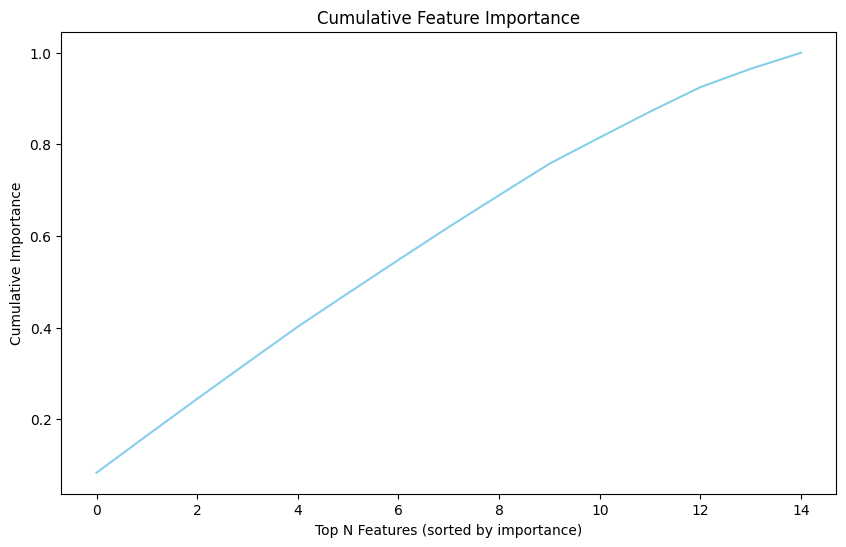

In [22]:
plt.figure(figsize=(10, 6))
plt.plot(importance_df['cumulative_importance'].sort_values(ascending=False), color='skyblue')
plt.title("Cumulative Feature Importance")
plt.xlabel("Top N Features (sorted by importance)")
plt.ylabel("Cumulative Importance")

## 7. ROC & Precision-Recall Curves

Both curves use `y_val_proba` (continuous probabilities) — this is what makes a
smooth curve possible; plotting against binary predictions (the original's bug)
collapses the curve to 3 points.

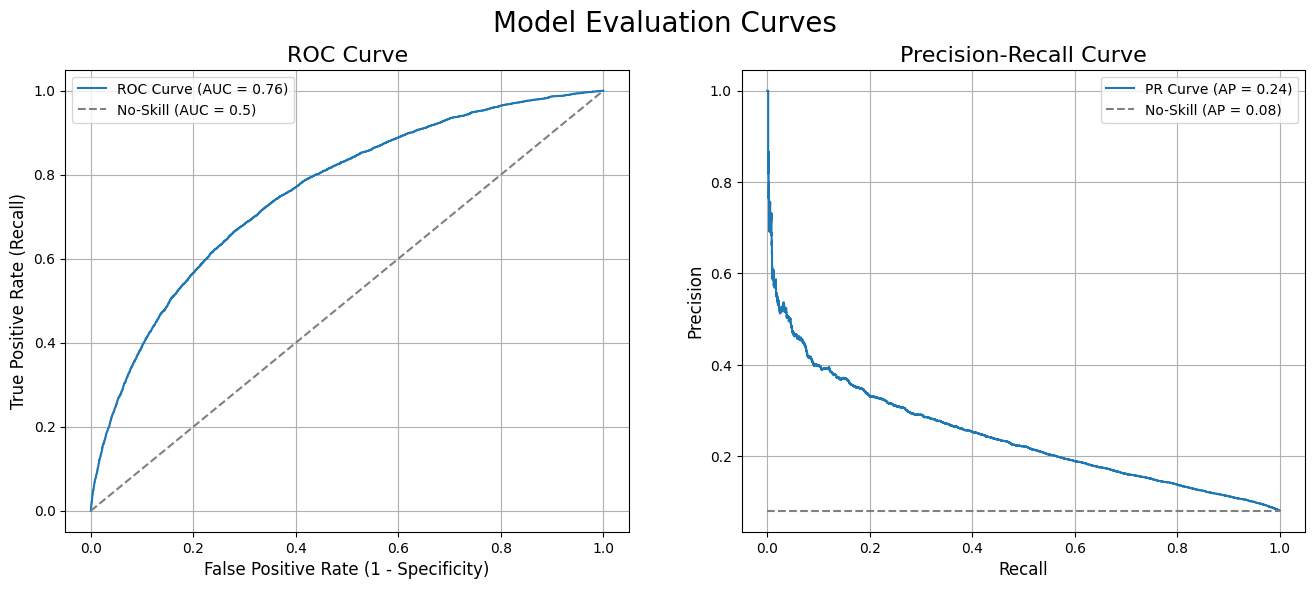

Saved evaluation curves.


In [12]:
fpr, tpr, _ = roc_curve(y_val, y_val_proba)
roc_auc_value = roc_auc_score(y_val, y_val_proba)

pr_precision, pr_recall, _ = precision_recall_curve(y_val, y_val_proba)
pr_auc_value = auc(pr_recall, pr_precision)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc_value:.2f})')
ax1.plot([0, 1], [0, 1], linestyle='--', color='gray', label='No-Skill (AUC = 0.5)')
ax1.set_title('ROC Curve', fontsize=16)
ax1.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax1.set_ylabel('True Positive Rate (Recall)', fontsize=12)
ax1.legend(); ax1.grid(True)

ax2.plot(pr_recall, pr_precision, label=f'PR Curve (AP = {pr_auc_value:.2f})')
no_skill = (y_val == 1).mean()
ax2.plot([0, 1], [no_skill, no_skill], linestyle='--', color='gray', label=f'No-Skill (AP = {no_skill:.2f})')
ax2.set_title('Precision-Recall Curve', fontsize=16)
ax2.set_xlabel('Recall', fontsize=12)
ax2.set_ylabel('Precision', fontsize=12)
ax2.legend(); ax2.grid(True)

fig.suptitle('Model Evaluation Curves', fontsize=20)
fig.savefig(os.path.join(MODEL_OUTPUT_DIR, 'model_evaluation_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

print("Saved evaluation curves.")

## 8. MLflow Tracking & Model Registration

Logs hyperparameters, metrics, plots, and a production-ready `pyfunc` wrapper that
handles categorical dtype reconstruction at inference time.

In [40]:
if ENABLE_MLFLOW:
    import mlflow
    import mlflow.pyfunc
    from mlflow.models import infer_signature
    from mlflow.tracking import MlflowClient

    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

    input_example  = X_val.head(3)
    output_example = final_model.predict(input_example)
    model_signature = infer_signature(input_example, output_example)

    print(f"MLflow tracking URI : {MLFLOW_TRACKING_URI}")
    print(f"MLflow experiment   : {MLFLOW_EXPERIMENT_NAME}")
else:
    print("ENABLE_MLFLOW=False — skipping MLflow tracking section.")

ENABLE_MLFLOW=False — skipping MLflow tracking section.


In [41]:
if ENABLE_MLFLOW:

    class LightGBMProductionWrapper(mlflow.pyfunc.PythonModel):
        """
        Wraps the trained LightGBM model so the MLflow pyfunc API can serve it.
        Reconstructs pandas 'category' dtype for categorical columns, since this
        information is lost when the model is served over JSON.
        """
        def __init__(self, trained_model, categorical_features):
            self.trained_model = trained_model
            self.categorical_features = categorical_features

        def predict(self, context, model_input):
            processed_df = model_input.copy()
            for col in self.categorical_features:
                if col in processed_df.columns:
                    processed_df[col] = processed_df[col].astype('category')
            probabilities = self.trained_model.predict_proba(processed_df)
            return probabilities[:, 1].tolist()

    cat_features = [col for col in X_val.columns if X_val[col].dtype.name == 'category']
    wrapped_production_model = LightGBMProductionWrapper(
        trained_model=final_model,
        categorical_features=cat_features,
    )
    print(f"Wrapped model with {len(cat_features)} categorical features.")

In [ ]:
if ENABLE_MLFLOW:

    with mlflow.start_run(run_name=MLFLOW_RUN_NAME) as run:
        mlflow.set_tag("model_name", MLFLOW_RUN_NAME)
        mlflow.log_params(resolved_best)
        mlflow.log_param("device", "cpu")
        mlflow.log_param("random_state", RANDOM_STATE)
        mlflow.log_param("test_size", TEST_SIZE)

        # Same hyperparameters as the log_params()/log_param() calls above, also
        # saved as a single downloadable JSON artifact -- useful for diffing
        # against another run's file, or reloading exactly as-is outside MLflow.
        hyperparameters_used = {
            **resolved_best,
            "device": "cpu",
            "random_state": RANDOM_STATE,
            "test_size": TEST_SIZE,
        }
        mlflow.log_dict(hyperparameters_used, "metadata/hyperparameters.json")

        mlflow.log_metric("val_auc", val_auc)
        mlflow.log_metric("val_f1_score", best_f1_score)
        mlflow.log_metric("val_threshold", best_threshold)
        mlflow.log_metric("val_log_loss", log_loss(y_val, y_val_proba))
        # FIX: log BOTH classes explicitly — class '1' (default) is the metric of interest
        mlflow.log_metric("val_precision_class1", report_df.loc['1', 'precision'])
        mlflow.log_metric("val_recall_class1",    report_df.loc['1', 'recall'])
        mlflow.log_metric("val_precision_class0", report_df.loc['0', 'precision'])
        mlflow.log_metric("val_recall_class0",    report_df.loc['0', 'recall'])

        mlflow.pyfunc.log_model(
            artifact_path="lightgbm_model",
            python_model=wrapped_production_model,
            registered_model_name=MLFLOW_REGISTERED_MODEL_NAME,
            signature=model_signature,
        )
        mlflow.log_figure(figure=fig, artifact_file="plots/ModelEvaluationCurves.png")
        mlflow.log_text(text=report_text, artifact_file="metadata/classification_report.txt")
        mlflow.log_artifact(
            local_path=os.path.join(MODEL_OUTPUT_DIR, 'lgbm_feature_importance.xlsx'),
            artifact_path="metadata",
        )

        print(f"Success! Run ID: {run.info.run_id}")

In [43]:
if ENABLE_MLFLOW:

    # FIX: client instantiated BEFORE use (original called it one cell too early)
    client = MlflowClient(tracking_uri=MLFLOW_TRACKING_URI)

    latest_versions = client.get_latest_versions(name=MLFLOW_REGISTERED_MODEL_NAME)
    newest_version = max(latest_versions, key=lambda v: int(v.version))

    # client.set_registered_model_alias(
    #     name=MLFLOW_REGISTERED_MODEL_NAME,
    #     alias="prod",
    #     version=newest_version.version,
    # )

    # Promotion to prod is a manual, deliberate gate — assign the alias yourself
    # in the MLflow UI (Models -> HomeCredit_Scorecard_Model -> select a version
    # -> Add alias -> 'prod') after reviewing this run's metrics.
    print(f"Registered model version: {newest_version.version}")
    print(f"Run ID for this version : {newest_version.run_id}")
    print("\n'prod' alias not set automatically — assign it manually in the MLflow UI "
          "once you've reviewed this run.")

### Viewing the MLflow UI

`mlflow ui` is a **shell command**, not Python — it must be run in a terminal, not
executed as a notebook cell (the original notebook had this as a bare code cell,
which raises a `SyntaxError` if run).

From a terminal, with the project root as the working directory:

```bash
mlflow ui --backend-store-uri "file:./data/mlruns"
```

## 9. Cleanup

In [44]:
del X_train, X_val, y_train, y_val, X, y, model_dataset
import gc; gc.collect()
print("All DataFrames released.")

All DataFrames released.
